In [1]:
# Core libraries
from pathlib import Path
import os
import statistics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyabf

# Signal-processing and statistical tools
from scipy import stats
from scipy.signal import (
    butter,
    filtfilt,
)
from scipy.stats import (
    kurtosis,
    skew,
)

Recording: T_g_CD_250805__0004
Sampling rate: 100,000 Hz
Processed duration: 385.00 s


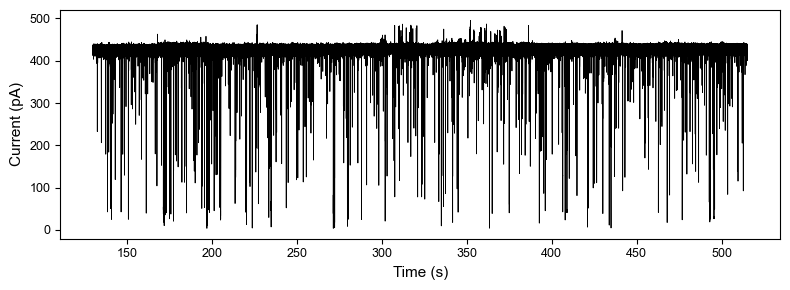

In [2]:
# Load and preprocess a representative ABF recording.

# For public use, place the example ABF file in the
# example_data folder and use the following path:
# DATA_DIR = Path(".")
# ABF_FILE = DATA_DIR / "example_data" / "T_g_CD_250805__0004.abf"

DATA_DIR = Path(
    "/Volumes/JAEONCHO/ADIC-AA/g_CD data"
)

ABF_FILE = (
    DATA_DIR
    / "g_CD_T"
    / "T_g_CD_250805__0004.abf"
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Processing parameters for the representative recording.
SWEEP_INDEX = 0
GAIN = 1
LOWPASS_HZ = None
PROCESS_START_S = 130
PROCESS_END_S = 515


def lowpass_filter(
    signal,
    cutoff_hz,
    sampling_rate,
    order=8,
):
    """Apply a Butterworth low-pass filter."""

    nyquist_frequency = (
        0.5 * sampling_rate
    )

    normalized_cutoff = (
        cutoff_hz
        / nyquist_frequency
    )

    filter_coefficients = butter(
        order,
        normalized_cutoff,
        btype="low",
    )

    return filtfilt(
        *filter_coefficients,
        signal,
    )


def load_abf(
    filepath,
    sweep_index=0,
    gain=10,
    lowpass_hz=1000,
    start_time=None,
    end_time=None,
):
    """Load one ABF sweep and apply optional preprocessing."""

    abf = pyabf.ABF(
        str(filepath)
    )

    abf.setSweep(
        sweep_index
    )

    # Current in pA and time in seconds.
    signal = abf.sweepY.copy()
    time = abf.sweepX.copy()
    sampling_rate = abf.dataRate

    # Apply gain correction.
    signal = signal / gain

    if lowpass_hz is not None:
        signal = lowpass_filter(
            signal=signal,
            cutoff_hz=lowpass_hz,
            sampling_rate=sampling_rate,
        )

    if (
        start_time is not None
        or end_time is not None
    ):
        selected_start = (
            0
            if start_time is None
            else start_time
        )

        selected_end = (
            time[-1]
            if end_time is None
            else end_time
        )

        time_mask = (
            (time >= selected_start)
            & (time <= selected_end)
        )

        time = time[time_mask]
        signal = signal[time_mask]

    return (
        time,
        signal,
        sampling_rate,
    )


time, signal, fs = load_abf(
    filepath=ABF_FILE,
    sweep_index=SWEEP_INDEX,
    gain=GAIN,
    lowpass_hz=LOWPASS_HZ,
    start_time=PROCESS_START_S,
    end_time=PROCESS_END_S,
)

# Retained for conversion between trace-relative indices
# and absolute recording time in downstream cells.
start_point = PROCESS_START_S

recording_id = ABF_FILE.stem

print(
    f"Recording: {recording_id}"
)

print(
    f"Sampling rate: {fs:,.0f} Hz"
)

print(
    f"Processed duration: "
    f"{time[-1] - time[0]:.2f} s"
)

plt.figure(figsize=(8, 3))

plt.plot(
    time,
    signal,
    color="black",
    linewidth=0.6,
)

plt.xlabel(
    "Time (s)",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "Current (pA)",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.tight_layout()
plt.show()

Open-pore RMS noise (σ0): 2.41 pA
Open-pore current (I0): 432.76 pA
Selected baseline range: 425.78–439.73 pA


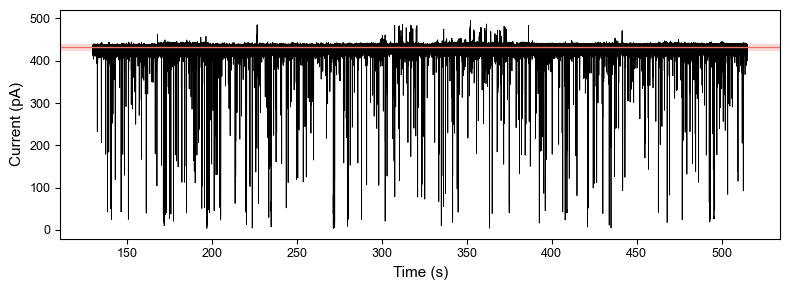

Baseline information saved to: /Volumes/JAEONCHO/ADIC-AA/g_CD data/final_baseline_info_g_CD/T_g_CD_250805__0004_final.csv


In [3]:
# Estimate the open-pore baseline and noise level σ0.

BASELINE_OUTPUT_DIR = (
    DATA_DIR
    / "final_baseline_info_g_CD"
)

BASELINE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

HISTOGRAM_BINS = 200

# This window is manually adjusted for each recording.
NOISE_WINDOW_PA = 7


def estimate_open_pore_noise(
    signal,
    number_of_bins=200,
    noise_window_pa=8,
):
    """Estimate the open-pore current and its noise."""

    histogram_counts, bin_edges = np.histogram(
        signal,
        bins=number_of_bins,
    )

    mode_bin_index = np.argmax(
        histogram_counts
    )

    open_pore_current = (
        bin_edges[mode_bin_index]
        + bin_edges[mode_bin_index + 1]
    ) / 2

    noise_mask = (
        (
            signal
            >= open_pore_current
            - noise_window_pa
        )
        & (
            signal
            <= open_pore_current
            + noise_window_pa
        )
    )

    noise_samples = signal[
        noise_mask
    ]

    if len(noise_samples) == 0:
        raise ValueError(
            "No current points were found within the "
            "selected open-pore noise window."
        )

    open_pore_rms = np.std(
        noise_samples
    )

    if (
        not np.isfinite(open_pore_rms)
        or open_pore_rms <= 0
    ):
        raise ValueError(
            "A valid open-pore noise value could not "
            "be calculated."
        )

    baseline_minimum = np.min(
        noise_samples
    )

    baseline_maximum = np.max(
        noise_samples
    )

    return {
        "baseline": open_pore_current,
        "rms": open_pore_rms,
        "baseline_minimum": baseline_minimum,
        "baseline_maximum": baseline_maximum,
        "noise_window_pa": noise_window_pa,
    }


baseline_results = estimate_open_pore_noise(
    signal=signal,
    number_of_bins=HISTOGRAM_BINS,
    noise_window_pa=NOISE_WINDOW_PA,
)

baseline_mean = baseline_results[
    "baseline"
]

rms_final = baseline_results[
    "rms"
]

bmin = baseline_results[
    "baseline_minimum"
]

bmax = baseline_results[
    "baseline_maximum"
]

noise_amplitude = baseline_results[
    "noise_window_pa"
]

print(
    f"Open-pore RMS noise (σ0): "
    f"{rms_final:.2f} pA"
)

print(
    f"Open-pore current (I0): "
    f"{baseline_mean:.2f} pA"
)

print(
    f"Selected baseline range: "
    f"{bmin:.2f}–{bmax:.2f} pA"
)

# Visualize the selected open-pore region.
plt.figure(figsize=(8, 3))

plt.plot(
    time,
    signal,
    color="black",
    linewidth=0.6,
)

plt.axhline(
    baseline_mean,
    color="#EC7166",
    linewidth=1,
)

plt.axhspan(
    baseline_mean - noise_amplitude,
    baseline_mean + noise_amplitude,
    color="#EC7166",
    alpha=0.20,
)

plt.xlabel(
    "Time (s)",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "Current (pA)",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.tight_layout()
plt.show()

# Save the baseline and open-pore noise used for
# downstream signal processing.
baseline_summary = pd.DataFrame({
    "baseline": [
        baseline_mean
    ],
    "rms": [
        rms_final
    ],
})

baseline_output_path = (
    BASELINE_OUTPUT_DIR
    / f"{recording_id}_final.csv"
)

baseline_summary.to_csv(
    baseline_output_path,
    index=False,
)

print(
    f"Baseline information saved to: "
    f"{baseline_output_path}"
)

In [4]:
# Detect first-level blockage events and extract
# their raw signal variables.

def generate_detection_parameters(
    open_pore_rms,
):
    """Generate recording-specific detection parameters."""

    return {
        "threshold":
            6 * open_pore_rms,

        "hysteresis":
            7 * open_pore_rms,

        "sensitivity":
            15 * open_pore_rms,

        "min_step":
            7.5 * open_pore_rms,

        "min_separation_us":
            100,

        "min_event_length_us":
            10_000,

        "max_event_length_us":
            10_000_000,

        "trim_slope_threshold":
            5,
    }


params = generate_detection_parameters(
    rms_final
)

print(
    "First-level detection parameters:"
)

for parameter_name, parameter_value in params.items():
    print(
        f"  {parameter_name}: "
        f"{parameter_value}"
    )


def get_stable_region(
    signal,
    center_index,
    direction,
    sampling_rate,
    maximum_duration_us=50_000,
    variability_threshold=2.0,
    minimum_index=None,
    maximum_index=None,
):
    """Collect a stable current region adjacent to an event."""

    maximum_samples = int(
        maximum_duration_us
        / 1e6
        * sampling_rate
    )

    minimum_samples = max(
        1,
        int(
            sampling_rate
            * 0.00001
        ),
    )

    segment = []

    for offset in range(
        maximum_samples
    ):
        index = (
            center_index
            + direction * offset
        )

        if (
            index < 0
            or index >= len(signal)
        ):
            break

        if (
            direction == -1
            and minimum_index is not None
            and index <= minimum_index
        ):
            break

        if (
            direction == 1
            and maximum_index is not None
            and index >= maximum_index
        ):
            break

        segment.append(
            signal[index]
        )

        if len(segment) >= minimum_samples:
            cumulative_stdev = np.std(
                segment
            )

            if (
                cumulative_stdev
                > variability_threshold
            ):
                break

    # Remove the first point that exceeded the
    # variability threshold.
    if len(segment) > 1:
        segment = segment[:-1]

    if direction == -1:
        segment = segment[::-1]

    return np.asarray(
        segment
    )


def detect_event_bounds(
    signal,
    sampling_rate,
    detection_parameters,
):
    """Detect the boundaries of first-level blockages."""

    baseline_sample_count = int(
        sampling_rate
    )

    initial_baseline = np.median(
        signal[:baseline_sample_count]
    )

    sensitivity = detection_parameters[
        "sensitivity"
    ]

    minimum_step = detection_parameters[
        "min_step"
    ]

    minimum_separation_samples = int(
        detection_parameters[
            "min_separation_us"
        ]
        / 1e6
        * sampling_rate
    )

    positive_cumulative_sum = 0
    negative_cumulative_sum = 0

    in_event = False
    last_step_index = -np.inf
    event_bounds = []

    for index in range(
        1,
        len(signal),
    ):
        current_value = signal[index]

        deviation = (
            current_value
            - initial_baseline
        )

        positive_cumulative_sum = max(
            0,
            positive_cumulative_sum
            + deviation,
        )

        negative_cumulative_sum = min(
            0,
            negative_cumulative_sum
            + deviation,
        )

        if not in_event:
            if (
                abs(negative_cumulative_sum)
                > sensitivity
            ):
                if (
                    index
                    - last_step_index
                    > minimum_separation_samples
                ):
                    in_event = True
                    event_start = index
                    last_step_index = index

                    positive_cumulative_sum = 0
                    negative_cumulative_sum = 0

        else:
            if abs(deviation) < minimum_step:
                in_event = False
                event_end = index

                duration_us = (
                    event_end
                    - event_start
                ) / sampling_rate * 1e6

                if (
                    detection_parameters[
                        "min_event_length_us"
                    ]
                    <= duration_us
                    <= detection_parameters[
                        "max_event_length_us"
                    ]
                ):
                    event_bounds.append(
                        (
                            event_start,
                            event_end,
                        )
                    )

    return event_bounds


def extract_event_features(
    signal,
    sampling_rate,
    detection_parameters,
    open_pore_rms,
    event_bounds,
    recording_start_time=0,
):
    """Extract raw variables from first-level blockages."""

    extracted_events = []

    for event_index, (
        event_start,
        event_end,
    ) in enumerate(event_bounds):
        duration_us = (
            event_end
            - event_start
        ) / sampling_rate * 1e6

        previous_event_end = (
            event_bounds[
                event_index - 1
            ][1]
            if event_index > 0
            else 0
        )

        next_event_start = (
            event_bounds[
                event_index + 1
            ][0]
            if (
                event_index
                < len(event_bounds) - 1
            )
            else len(signal)
        )

        before_segment = get_stable_region(
            signal=signal,
            center_index=event_start,
            direction=-1,
            sampling_rate=sampling_rate,
            variability_threshold=open_pore_rms,
            minimum_index=previous_event_end,
            maximum_index=next_event_start,
        )

        after_segment = get_stable_region(
            signal=signal,
            center_index=event_end,
            direction=1,
            sampling_rate=sampling_rate,
            variability_threshold=open_pore_rms,
            minimum_index=previous_event_end,
            maximum_index=next_event_start,
        )

        if (
            len(before_segment) == 0
            or len(after_segment) == 0
        ):
            continue

        event_signal = signal[
            event_start:event_end
        ]

        if len(event_signal) == 0:
            continue

        local_open_pore_current = np.mean(
            before_segment
        )

        blockage_mean = np.mean(
            event_signal
        )

        blockage_mode = stats.mode(
            event_signal,
            keepdims=False,
        ).mode

        event = {
            "event_signal":
                event_signal,

            "start_idx":
                event_start,

            "end_idx":
                event_end,

            "start_time_s":
                (
                    recording_start_time
                    + event_start
                    / sampling_rate
                ),

            "end_time_s":
                (
                    recording_start_time
                    + event_end
                    / sampling_rate
                ),

            "depth_pA":
                (
                    local_open_pore_current
                    - np.min(event_signal)
                ),

            "pre_interaction_signal":
                before_segment,

            "pre_interaction_current":
                np.mean(before_segment),

            "pre_interaction_stdev":
                np.std(before_segment),

            "pre_interaction_duration_us":
                (
                    len(before_segment)
                    / sampling_rate
                    * 1e6
                ),

            "post_interaction_signal":
                after_segment,

            "post_interaction_current":
                np.mean(after_segment),

            "post_interaction_stdev":
                np.std(after_segment),

            "post_interaction_duration_us":
                (
                    len(after_segment)
                    / sampling_rate
                    * 1e6
                ),

            "open_pore_current":
                local_open_pore_current,

            "blockage_current":
                (
                    local_open_pore_current
                    - blockage_mean
                ),

            # σ1
            "blockage_stdev":
                np.std(event_signal),

            "blockage_mean":
                blockage_mean,

            # Initial I1 estimate; refined in the next cell.
            "blockage_mode":
                blockage_mode,

            # Δt1
            "dwell_time_us":
                duration_us,
        }

        extracted_events.append(
            event
        )

    return extracted_events


event_bounds = detect_event_bounds(
    signal=signal,
    sampling_rate=fs,
    detection_parameters=params,
)

events = extract_event_features(
    signal=signal,
    sampling_rate=fs,
    detection_parameters=params,
    open_pore_rms=rms_final,
    event_bounds=event_bounds,
    recording_start_time=start_point,
)

print(
    f"Detected first-level events: "
    f"{len(events):,}"
)

First-level detection parameters:
  threshold: 14.437685012817383
  hysteresis: 16.843965530395508
  sensitivity: 36.09421157836914
  min_step: 18.04710578918457
  min_separation_us: 100
  min_event_length_us: 10000
  max_event_length_us: 10000000
  trim_slope_threshold: 5
Detected first-level events: 45


In [5]:
# Refine the first-level event boundaries and update
# I1, σ1, and the first-level blockage measurements.

def trim_event_edge(
    signal,
    start_index,
    stop_index,
    direction="forward",
    slope_threshold=5,
):
    """Trim the steep transition at one event boundary."""

    step = (
        1
        if direction == "forward"
        else -1
    )

    previous_value = signal[
        start_index
    ]

    current_index = start_index

    while current_index != stop_index:
        current_index += step

        if (
            current_index < 1
            or current_index >= len(signal)
        ):
            break

        slope = abs(
            signal[current_index]
            - previous_value
        )

        if slope < slope_threshold:
            break

        previous_value = signal[
            current_index
        ]

    return current_index


def refine_event_bounds(
    signal,
    event_bounds,
    slope_threshold,
):
    """Trim both boundaries of each detected event."""

    refined_bounds = []

    for event_start, event_end in event_bounds:
        refined_start = trim_event_edge(
            signal=signal,
            start_index=event_start,
            stop_index=event_end,
            direction="forward",
            slope_threshold=slope_threshold,
        )

        refined_end = trim_event_edge(
            signal=signal,
            start_index=event_end,
            stop_index=event_start,
            direction="backward",
            slope_threshold=slope_threshold,
        )

        if refined_start >= refined_end:
            raise ValueError(
                "Invalid event boundaries were produced "
                f"for the event at indices "
                f"{event_start}:{event_end}."
            )

        refined_bounds.append(
            (
                refined_start,
                refined_end,
            )
        )

    return refined_bounds


def extract_refined_event_features(
    signal,
    sampling_rate,
    open_pore_rms,
    refined_event_bounds,
    recording_start_time=0,
):
    """Extract raw variables from refined event regions."""

    refined_events = []

    for event_index, (
        event_start,
        event_end,
    ) in enumerate(
        refined_event_bounds
    ):
        previous_event_end = (
            refined_event_bounds[
                event_index - 1
            ][1]
            if event_index > 0
            else 0
        )

        next_event_start = (
            refined_event_bounds[
                event_index + 1
            ][0]
            if (
                event_index
                < len(refined_event_bounds) - 1
            )
            else len(signal)
        )

        before_segment = get_stable_region(
            signal=signal,
            center_index=event_start,
            direction=-1,
            sampling_rate=sampling_rate,
            variability_threshold=open_pore_rms,
            minimum_index=previous_event_end,
            maximum_index=next_event_start,
        )

        after_segment = get_stable_region(
            signal=signal,
            center_index=event_end,
            direction=1,
            sampling_rate=sampling_rate,
            variability_threshold=open_pore_rms,
            minimum_index=previous_event_end,
            maximum_index=next_event_start,
        )

        if (
            len(before_segment) == 0
            or len(after_segment) == 0
        ):
            raise ValueError(
                "A stable current region could not be "
                f"identified for refined event "
                f"{event_index}."
            )

        event_signal = signal[
            event_start:event_end
        ]

        if len(event_signal) == 0:
            raise ValueError(
                f"Refined event {event_index} "
                "contains no current points."
            )

        local_open_pore_current = np.mean(
            before_segment
        )

        blockage_mean = np.mean(
            event_signal
        )

        blockage_mode = stats.mode(
            event_signal,
            keepdims=False,
        ).mode

        duration_us = (
            event_end
            - event_start
        ) / sampling_rate * 1e6

        refined_events.append({
            "event_signal":
                event_signal,

            "start_idx":
                event_start,

            "end_idx":
                event_end,

            "start_time_s":
                (
                    recording_start_time
                    + event_start
                    / sampling_rate
                ),

            "end_time_s":
                (
                    recording_start_time
                    + event_end
                    / sampling_rate
                ),

            "depth_pA":
                (
                    local_open_pore_current
                    - np.min(event_signal)
                ),

            "pre_interaction_signal":
                before_segment,

            "pre_interaction_current":
                np.mean(before_segment),

            "pre_interaction_stdev":
                np.std(before_segment),

            "pre_interaction_duration_us":
                (
                    len(before_segment)
                    / sampling_rate
                    * 1e6
                ),

            "post_interaction_signal":
                after_segment,

            "post_interaction_current":
                np.mean(after_segment),

            "post_interaction_stdev":
                np.std(after_segment),

            "post_interaction_duration_us":
                (
                    len(after_segment)
                    / sampling_rate
                    * 1e6
                ),

            "open_pore_current":
                local_open_pore_current,

            "blockage_current":
                (
                    local_open_pore_current
                    - blockage_mean
                ),

            # σ1
            "blockage_stdev":
                np.std(event_signal),

            "blockage_mean":
                blockage_mean,

            # I1
            "blockage_mode":
                blockage_mode,

            "dwell_time_us":
                duration_us,
        })

    return refined_events


trim_event_bounds = refine_event_bounds(
    signal=signal,
    event_bounds=event_bounds,
    slope_threshold=params[
        "trim_slope_threshold"
    ],
)

trim_events = extract_refined_event_features(
    signal=signal,
    sampling_rate=fs,
    open_pore_rms=rms_final,
    refined_event_bounds=trim_event_bounds,
    recording_start_time=start_point,
)

if len(events) != len(trim_events):
    raise ValueError(
        "The numbers of detected and refined events "
        "do not match."
    )

# Retain the originally detected event duration and
# boundaries while replacing its first-level current
# statistics with values from the refined region.
for event, refined_event in zip(
    events,
    trim_events,
):
    event["blockage_current"] = (
        event["open_pore_current"]
        - refined_event["blockage_mode"]
    )

    event["blockage_stdev"] = (
        refined_event["blockage_stdev"]
    )

    event["blockage_mean"] = (
        refined_event["blockage_mean"]
    )

    event["blockage_mode"] = (
        refined_event["blockage_mode"]
    )

print(
    f"Refined first-level events: "
    f"{len(trim_events):,}"
)

Refined first-level events: 45


In [6]:
# Detect secondary events within each first-level
# blockage and extract their raw variables.

def generate_secondary_detection_parameters(
    open_pore_rms,
):
    """Generate secondary-event detection parameters."""

    return {
        "threshold":
            6 * open_pore_rms,

        "hysteresis":
            7 * open_pore_rms,

        "sensitivity":
            15 * open_pore_rms,

        "min_step":
            7.5 * open_pore_rms,

        "min_separation_us":
            100,

        "min_event_length_us":
            100,

        "max_event_length_us":
            100_000,

        "trim_slope_threshold":
            5,
    }


def extract_secondary_event_features(
    signal,
    sampling_rate,
    event_bounds,
    first_level_current,
    open_pore_rms,
    parent_start_time=0,
):
    """Extract raw variables from secondary events."""

    secondary_events = []
    secondary_blockage_summaries = []

    for event_index, (
        event_start,
        event_end,
    ) in enumerate(event_bounds):
        previous_event_end = (
            event_bounds[
                event_index - 1
            ][1]
            if event_index > 0
            else 0
        )

        next_event_start = (
            event_bounds[
                event_index + 1
            ][0]
            if (
                event_index
                < len(event_bounds) - 1
            )
            else len(signal)
        )

        before_segment = get_stable_region(
            signal=signal,
            center_index=event_start,
            direction=-1,
            sampling_rate=sampling_rate,
            variability_threshold=open_pore_rms,
            minimum_index=previous_event_end,
            maximum_index=next_event_start,
        )

        after_segment = get_stable_region(
            signal=signal,
            center_index=event_end,
            direction=1,
            sampling_rate=sampling_rate,
            variability_threshold=open_pore_rms,
            minimum_index=previous_event_end,
            maximum_index=next_event_start,
        )

        if (
            len(before_segment) == 0
            or len(after_segment) == 0
        ):
            continue

        secondary_event_signal = signal[
            event_start:event_end
        ]

        if len(secondary_event_signal) == 0:
            continue

        secondary_local_baseline = np.mean(
            before_segment
        )

        secondary_blockage_mean = np.mean(
            secondary_event_signal
        )

        secondary_blockage_current = (
            first_level_current
            - secondary_blockage_mean
        )

        duration_us = (
            event_end
            - event_start
        ) / sampling_rate * 1e6

        secondary_event = {
            "sub_event_signal":
                secondary_event_signal,

            "sub_start_idx":
                event_start,

            "sub_end_idx":
                event_end,

            "sub_start_time_s":
                (
                    parent_start_time
                    + event_start
                    / sampling_rate
                ),

            "sub_end_time_s":
                (
                    parent_start_time
                    + event_end
                    / sampling_rate
                ),

            "sub_depth_pA":
                (
                    first_level_current
                    - np.min(
                        secondary_event_signal
                    )
                ),

            "sub_pre_interaction_signal":
                before_segment,

            "sub_pre_interaction_current":
                np.mean(before_segment),

            "sub_pre_interaction_stdev":
                np.std(before_segment),

            "sub_pre_interaction_duration_us":
                (
                    len(before_segment)
                    / sampling_rate
                    * 1e6
                ),

            # Post-interaction region used to define I1*.
            "sub_post_interaction_signal":
                after_segment,

            # I1*
            "sub_post_interaction_current":
                np.mean(after_segment),

            # σ1*
            "sub_post_interaction_stdev":
                np.std(after_segment),

            "sub_post_interaction_duration_us":
                (
                    len(after_segment)
                    / sampling_rate
                    * 1e6
                ),

            "sub_open_pore_current":
                secondary_local_baseline,

            "sub_blockage_current":
                secondary_blockage_current,

            "sub_blockage_stdev":
                np.std(
                    secondary_event_signal
                ),

            "sub_blockage_mean":
                secondary_blockage_mean,

            "sub_dwell_time_us":
                duration_us,

            # I1 of the parent first-level blockage.
            "sub_mode_baseline":
                first_level_current,
        }

        secondary_events.append(
            secondary_event
        )

        secondary_blockage_summaries.append({
            "sub_blockage_current":
                secondary_blockage_current,
        })

    return (
        secondary_events,
        secondary_blockage_summaries,
    )


sub_params = (
    generate_secondary_detection_parameters(
        rms_final
    )
)

all_sub_events = []

# Retain results separately for each parent first-level
# blockage so they can be incorporated in the next cell
# without repeating secondary-event detection.
sub_events_by_parent = []
sub_blockage_summaries_by_parent = []

for parent_event in events:
    sub_event_bounds = detect_event_bounds(
        signal=parent_event["event_signal"],
        sampling_rate=fs,
        detection_parameters=sub_params,
    )

    (
        parent_sub_events,
        parent_sub_blockage_summaries,
    ) = extract_secondary_event_features(
        signal=parent_event["event_signal"],
        sampling_rate=fs,
        event_bounds=sub_event_bounds,
        first_level_current=parent_event[
            "blockage_mode"
        ],
        open_pore_rms=rms_final,
        parent_start_time=parent_event[
            "start_time_s"
        ],
    )

    sub_events_by_parent.append(
        parent_sub_events
    )

    sub_blockage_summaries_by_parent.append(
        parent_sub_blockage_summaries
    )

    all_sub_events.extend(
        parent_sub_events
    )

print(
    f"Detected secondary events: "
    f"{len(all_sub_events):,}"
)

print(
    f"Parent first-level events: "
    f"{len(events):,}"
)

Detected secondary events: 385
Parent first-level events: 45


In [7]:
# Incorporate secondary-event information into each
# parent first-level event.

if not (
    len(events)
    == len(sub_events_by_parent)
    == len(
        sub_blockage_summaries_by_parent
    )
):
    raise ValueError(
        "The parent-event and secondary-event result "
        "counts do not match."
    )


def estimate_histogram_mode(
    values,
):
    """Estimate the mode using automatically selected bins."""

    histogram_counts, bin_edges = np.histogram(
        values,
        bins="auto",
    )

    mode_bin_index = np.argmax(
        histogram_counts
    )

    return bin_edges[
        mode_bin_index
    ]


for parent_event_index, (
    parent_event,
    parent_sub_events,
    parent_sub_blockage_summaries,
) in enumerate(
    zip(
        events,
        sub_events_by_parent,
        sub_blockage_summaries_by_parent,
    )
):
    # Retain an explicit parent-event index so that
    # secondary events can later be linked or removed
    # without relying on shared current values.
    for secondary_event in parent_sub_events:
        secondary_event[
            "parent_event_index"
        ] = parent_event_index

    parent_event["sub_event"] = (
        parent_sub_blockage_summaries
    )

    number_of_sub_events = len(
        parent_sub_events
    )

    # nsec
    parent_event["num_sub_events"] = (
        number_of_sub_events
    )

    if number_of_sub_events == 0:
        parent_event[
            "mean_sub_blockage_current"
        ] = 0

        parent_event[
            "std_sub_blockage_current"
        ] = 0

        continue

    sub_blockage_values = [
        secondary_event[
            "sub_blockage_current"
        ]
        for secondary_event
        in parent_sub_events
    ]

    sub_dwell_times = [
        secondary_event[
            "sub_dwell_time_us"
        ]
        for secondary_event
        in parent_sub_events
    ]

    sub_pre_interaction_currents = [
        secondary_event[
            "sub_pre_interaction_current"
        ]
        for secondary_event
        in parent_sub_events
    ]

    sub_pre_interaction_stdevs = [
        secondary_event[
            "sub_pre_interaction_stdev"
        ]
        for secondary_event
        in parent_sub_events
    ]

    sub_post_interaction_currents = [
        secondary_event[
            "sub_post_interaction_current"
        ]
        for secondary_event
        in parent_sub_events
    ]

    sub_post_interaction_stdevs = [
        secondary_event[
            "sub_post_interaction_stdev"
        ]
        for secondary_event
        in parent_sub_events
    ]

    parent_event[
        "mean_sub_blockage_current"
    ] = np.mean(
        sub_blockage_values
    )

    parent_event[
        "median_sub_blockage_current"
    ] = np.median(
        sub_blockage_values
    )

    parent_event[
        "mode_sub_blockage_current"
    ] = estimate_histogram_mode(
        sub_blockage_values
    )

    parent_event[
        "mean_sub_dwell_time_us"
    ] = np.mean(
        sub_dwell_times
    )

    parent_event[
        "median_sub_dwell_time_us"
    ] = np.median(
        sub_dwell_times
    )

    parent_event[
        "mode_sub_dwell_time_us"
    ] = estimate_histogram_mode(
        sub_dwell_times
    )

    parent_event["big_drop_count"] = sum(
        blockage_current > 50
        for blockage_current
        in sub_blockage_values
    )

    parent_event[
        "mean_sub_pre_interaction_current"
    ] = np.mean(
        sub_pre_interaction_currents
    )

    parent_event[
        "mean_sub_pre_interaction_stdev"
    ] = np.mean(
        sub_pre_interaction_stdevs
    )

    parent_event[
        "mean_sub_post_interaction_current"
    ] = np.mean(
        sub_post_interaction_currents
    )

    parent_event[
        "mean_sub_post_interaction_stdev"
    ] = np.mean(
        sub_post_interaction_stdevs
    )

    if number_of_sub_events > 1:
        parent_event[
            "std_sub_blockage_current"
        ] = statistics.stdev(
            sub_blockage_values
        )

        parent_event[
            "std_sub_pre_interaction_current"
        ] = statistics.stdev(
            sub_pre_interaction_currents
        )

        parent_event[
            "std_sub_pre_interaction_stdev"
        ] = statistics.stdev(
            sub_pre_interaction_stdevs
        )

        parent_event[
            "std_sub_post_interaction_current"
        ] = statistics.stdev(
            sub_post_interaction_currents
        )

        parent_event[
            "std_sub_post_interaction_stdev"
        ] = statistics.stdev(
            sub_post_interaction_stdevs
        )

    else:
        parent_event[
            "std_sub_blockage_current"
        ] = 0

        parent_event[
            "std_sub_pre_interaction_current"
        ] = 0

        parent_event[
            "std_sub_pre_interaction_stdev"
        ] = 0

        parent_event[
            "std_sub_post_interaction_current"
        ] = 0

        parent_event[
            "std_sub_post_interaction_stdev"
        ] = 0


sub_event_counts = [
    event["num_sub_events"]
    for event in events
]

print(
    f"First-level events with secondary events: "
    f"{sum(count > 0 for count in sub_event_counts):,}"
)

print(
    f"Total secondary events: "
    f"{sum(sub_event_counts):,}"
)

First-level events with secondary events: 31
Total secondary events: 385


In [8]:
# Identify first-level blockages with fewer than two
# detected secondary events.

MINIMUM_SECONDARY_EVENTS = 2

remove_idx = [
    event_index
    for event_index, event in enumerate(
        events
    )
    if (
        event["num_sub_events"]
        < MINIMUM_SECONDARY_EVENTS
    )
]

retained_event_indices = [
    event_index
    for event_index in range(
        len(events)
    )
    if event_index not in set(
        remove_idx
    )
]

print(
    f"Excluded first-level events: "
    f"{len(remove_idx):,}"
)

print(
    f"Retained first-level events: "
    f"{len(retained_event_indices):,}"
)

print(
    "Excluded parent-event indices:",
    remove_idx,
)

Excluded first-level events: 15
Retained first-level events: 30
Excluded parent-event indices: [5, 6, 8, 13, 14, 15, 16, 17, 23, 28, 29, 33, 41, 43, 44]


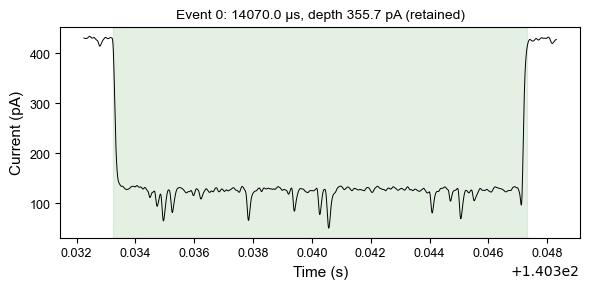

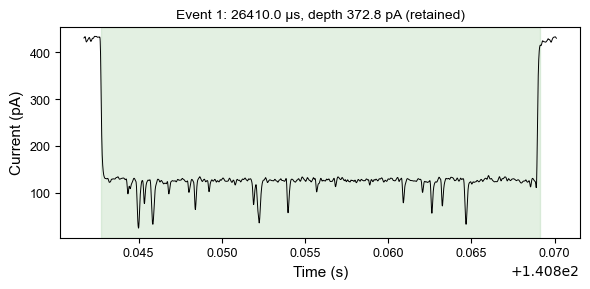

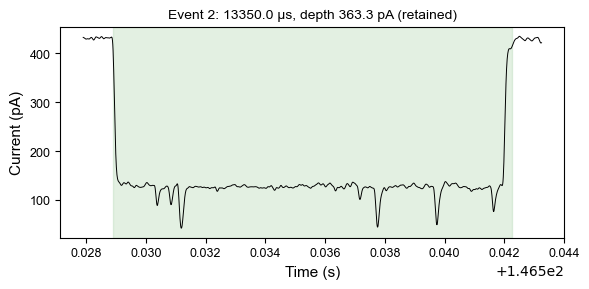

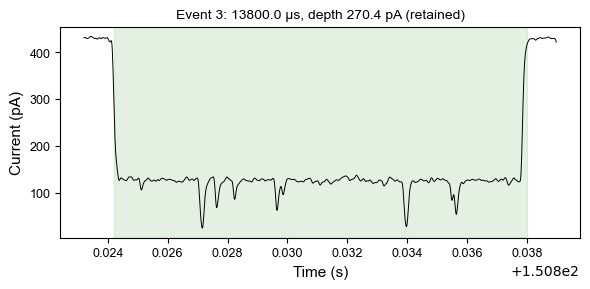

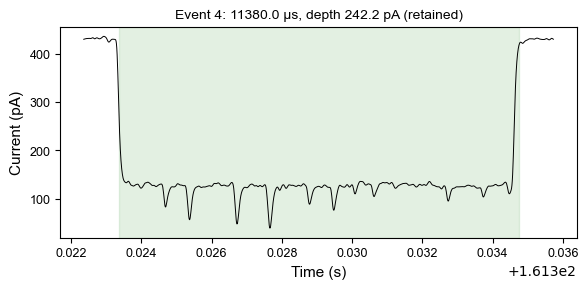

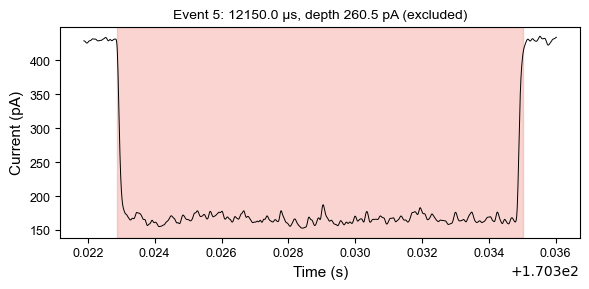

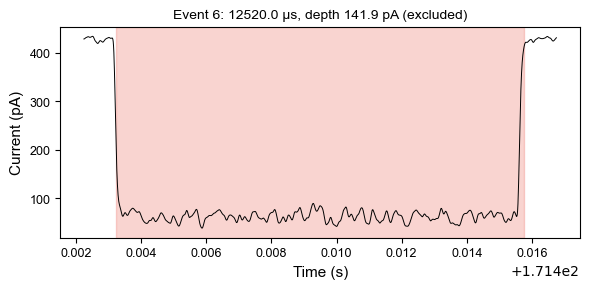

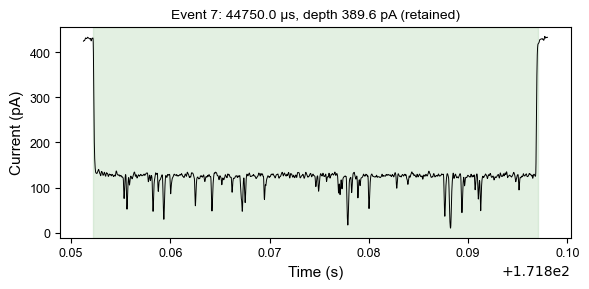

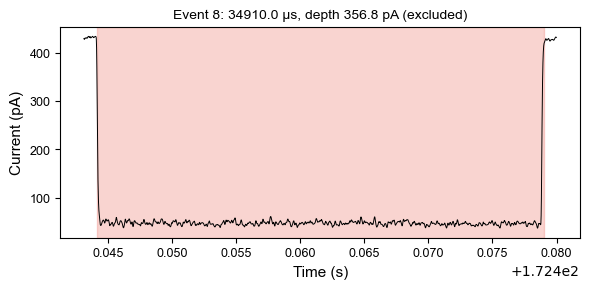

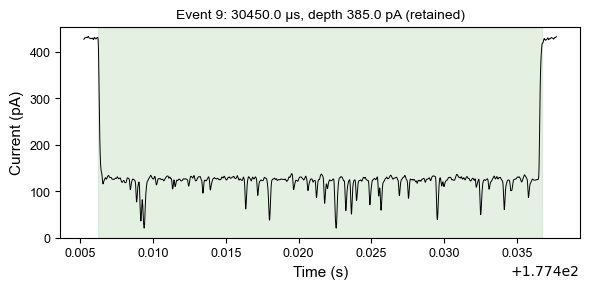

In [9]:
# Visualize detected first-level blockage events.

def plot_detected_events(
    time,
    signal,
    events,
    maximum_events=10,
    full_trace=False,
    padding_samples=100,
):
    """Plot detected events on the full trace or individually."""

    if full_trace:
        plt.figure(figsize=(10, 3))

        plt.plot(
            time,
            signal,
            color="black",
            linewidth=0.5,
        )

        for event_index, event in enumerate(
            events
        ):
            event_color = (
                "#A3CFA2"
                if event_index
                in retained_event_indices
                else "#EC7166"
            )

            plt.axvspan(
                time[event["start_idx"]],
                time[event["end_idx"]],
                color=event_color,
                alpha=0.30,
            )

        plt.xlabel(
            "Time (s)",
            fontsize=11,
            fontfamily="Arial",
        )

        plt.ylabel(
            "Current (pA)",
            fontsize=11,
            fontfamily="Arial",
        )

        plt.xticks(
            fontsize=9,
            fontfamily="Arial",
        )

        plt.yticks(
            fontsize=9,
            fontfamily="Arial",
        )

        plt.tight_layout()
        plt.show()

        return

    number_to_plot = min(
        maximum_events,
        len(events),
    )

    for event_index, event in enumerate(
        events[:number_to_plot]
    ):
        plot_start = max(
            0,
            event["start_idx"]
            - padding_samples,
        )

        plot_end = min(
            len(signal),
            event["end_idx"]
            + padding_samples,
        )

        event_color = (
            "#A3CFA2"
            if event_index
            in retained_event_indices
            else "#EC7166"
        )

        event_status = (
            "retained"
            if event_index
            in retained_event_indices
            else "excluded"
        )

        plt.figure(figsize=(6, 3))

        plt.plot(
            time[plot_start:plot_end],
            signal[plot_start:plot_end],
            color="black",
            linewidth=0.7,
        )

        plt.axvspan(
            time[event["start_idx"]],
            time[event["end_idx"]],
            color=event_color,
            alpha=0.30,
        )

        plt.xlabel(
            "Time (s)",
            fontsize=11,
            fontfamily="Arial",
        )

        plt.ylabel(
            "Current (pA)",
            fontsize=11,
            fontfamily="Arial",
        )

        plt.title(
            (
                f"Event {event_index}: "
                f"{event['dwell_time_us']:.1f} μs, "
                f"depth {event['depth_pA']:.1f} pA "
                f"({event_status})"
            ),
            fontsize=10,
            fontfamily="Arial",
        )

        plt.xticks(
            fontsize=9,
            fontfamily="Arial",
        )

        plt.yticks(
            fontsize=9,
            fontfamily="Arial",
        )

        plt.tight_layout()
        plt.show()


# Change maximum_events to len(events) to inspect every
# detected first-level event.
plot_detected_events(
    time=time,
    signal=signal,
    events=events,
    maximum_events=10,
    full_trace=False,
)

In [10]:
# Convert retained first-level events to a DataFrame.

EVENT_OUTPUT_DIR = (
    DATA_DIR / "events_g_CD"
)

EVENT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

EVENT_FEATURE_KEYS = [
    "start_time_s",
    "end_time_s",
    "open_pore_current",
    "pre_interaction_current",
    "pre_interaction_stdev",
    "pre_interaction_duration_us",
    "depth_pA",
    "blockage_current",
    "blockage_stdev",
    "blockage_mean",
    "dwell_time_us",
    "post_interaction_current",
    "post_interaction_stdev",
    "post_interaction_duration_us",
    "mean_sub_blockage_current",
    "median_sub_blockage_current",
    "mode_sub_blockage_current",
    "mean_sub_dwell_time_us",
    "median_sub_dwell_time_us",
    "mode_sub_dwell_time_us",
    "std_sub_blockage_current",
    "num_sub_events",
    "big_drop_count",
    "sub_event",
    "mean_sub_pre_interaction_current",
    "mean_sub_pre_interaction_stdev",
    "std_sub_pre_interaction_current",
    "std_sub_pre_interaction_stdev",
    "mean_sub_post_interaction_current",
    "mean_sub_post_interaction_stdev",
    "std_sub_post_interaction_current",
    "std_sub_post_interaction_stdev",
]


def records_to_dataframe(
    records,
    feature_keys,
    index_name="event_index",
):
    """Convert extracted event dictionaries to a DataFrame."""

    rows = []

    for record_index, record in enumerate(
        records
    ):
        row = {
            feature_name: record.get(
                feature_name,
                np.nan,
            )
            for feature_name
            in feature_keys
        }

        row[index_name] = record_index

        rows.append(
            row
        )

    return pd.DataFrame(
        rows,
        columns=[
            index_name,
            *feature_keys,
        ],
    )


event_df = records_to_dataframe(
    records=events,
    feature_keys=EVENT_FEATURE_KEYS,
)

# Retain only first-level events containing at least
# two detected secondary events.
event_df = (
    event_df.loc[
        event_df["event_index"].isin(
            retained_event_indices
        )
    ]
    .copy()
    .reset_index(drop=True)
)


def extract_sub_blockage_values(
    secondary_event_summaries,
):
    """Extract secondary blockage-current values."""

    if not isinstance(
        secondary_event_summaries,
        list,
    ):
        return []

    return [
        summary[
            "sub_blockage_current"
        ]
        for summary
        in secondary_event_summaries
    ]


event_df["sub_blockage_values"] = (
    event_df["sub_event"]
    .apply(
        extract_sub_blockage_values
    )
)

event_df["sub_blockage_kurtosis"] = (
    event_df["sub_blockage_values"]
    .apply(
        lambda values: (
            kurtosis(
                values,
                fisher=False,
            )
            if len(values) >= 2
            else np.nan
        )
    )
)

event_df["sub_blockage_skewness"] = (
    event_df["sub_blockage_values"]
    .apply(
        lambda values: (
            skew(values)
            if len(values) >= 2
            else np.nan
        )
    )
)

# The nested list was used only to calculate the
# distribution statistics above.
event_df = event_df.drop(
    columns="sub_event"
)

print(
    f"Retained first-level events: "
    f"{len(event_df):,}"
)

display(
    event_df.head()
)

Retained first-level events: 30


,event_index,start_time_s,end_time_s,open_pore_current,pre_interaction_current,pre_interaction_stdev,pre_interaction_duration_us,depth_pA,blockage_current,blockage_stdev,...,mean_sub_pre_interaction_stdev,std_sub_pre_interaction_current,std_sub_pre_interaction_stdev,mean_sub_post_interaction_current,mean_sub_post_interaction_stdev,std_sub_post_interaction_current,std_sub_post_interaction_stdev,sub_blockage_values,sub_blockage_kurtosis,sub_blockage_skewness
0,0,140.33325,140.34732,406.005829,406.005829,0.0,10.0,355.682343,276.123047,25.086584,...,0.000000,12.156945,0.000000,113.280609,2.078278,1.135908,0.153381,"[29.179886, 48.220116, 44.895164, 35.71319, 39...",2.214548,-0.060161
1,1,140.84271,140.86912,397.399872,397.399872,0.0,10.0,372.772186,271.514862,23.515738,...,0.217014,8.050802,0.651042,112.237709,1.983063,1.228341,0.299322,"[63.735348, 60.233482, 41.036606, 34.425735, 6...",1.233640,0.043103
2,2,146.52890,146.54225,405.609100,405.609100,0.0,10.0,363.311737,278.869598,36.655727,...,0.000000,18.142871,0.000000,112.124115,1.949365,1.667635,0.276580,"[30.932617, 59.37195, 56.884766, 49.317932]",2.017959,-0.810691
3,3,150.82420,150.83800,295.227020,295.227020,0.0,10.0,270.355194,168.426483,28.540205,...,0.389162,26.159358,0.953248,113.241821,2.051049,1.507106,0.295030,"[64.88927, 41.752113, 30.576073, 42.458923, 71...",1.767416,0.385646
4,4,161.32336,161.33474,281.616180,281.616180,0.0,10.0,242.187469,153.564438,27.591837,...,0.000000,10.388154,0.000000,112.358093,1.990858,1.266206,0.254535,"[34.163246, 49.36666, 53.08773, 57.554688, 31....",1.429622,-0.019707


In [11]:
# Convert secondary events to a DataFrame and remove
# secondary events belonging to excluded parent events.

SUB_EVENT_OUTPUT_DIR = (
    DATA_DIR / "sub_events_g_CD"
)

SUB_EVENT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SUB_EVENT_FEATURE_KEYS = [
    "parent_event_index",
    "sub_start_time_s",
    "sub_end_time_s",
    "sub_depth_pA",
    "sub_open_pore_current",
    "sub_blockage_current",
    "sub_blockage_stdev",
    "sub_blockage_mean",
    "sub_dwell_time_us",
    "sub_mode_baseline",
    "sub_pre_interaction_current",
    "sub_pre_interaction_stdev",
    "sub_pre_interaction_duration_us",
    "sub_post_interaction_current",
    "sub_post_interaction_stdev",
    "sub_post_interaction_duration_us",
]

sub_event_df = records_to_dataframe(
    records=all_sub_events,
    feature_keys=SUB_EVENT_FEATURE_KEYS,
    index_name="sub_event_index",
)

# Remove secondary events belonging to first-level
# blockages that contained fewer than two secondary events.
sub_event_df = (
    sub_event_df.loc[
        ~sub_event_df[
            "parent_event_index"
        ].isin(remove_idx)
    ]
    .copy()
)

# Manual artifact exclusion
#
# All automatically detected events were visually checked
# against the corresponding raw current trace. Rare events
# were manually excluded only when they clearly did not
# exhibit the expected blockade morphology. Examples
# included current changes in the opposite direction from
# the predominant blockades, changes close to zero that did
# not represent a meaningful blockage, and obvious pore-
# instability or voltage-switching artifacts.
#
# The excluded parent-event indices are listed explicitly
# below so that the exclusion remains transparent and
# reproducible. This is separate from the subsequent
# statistical outlier removal using MAD.

MANUALLY_EXCLUDED_EVENT_INDICES = [
    
]

# Confirm that all listed indices exist.
unknown_manual_indices = sorted(
    set(
        MANUALLY_EXCLUDED_EVENT_INDICES
    )
    - set(
        range(len(events))
    )
)

if unknown_manual_indices:
    raise ValueError(
        "Unknown manually excluded parent-event "
        f"indices: {unknown_manual_indices}"
    )

# Remove manually identified artifacts from both the
# first-level and secondary-event DataFrames.
event_df = (
    event_df.loc[
        ~event_df["event_index"].isin(
            MANUALLY_EXCLUDED_EVENT_INDICES
        )
    ]
    .copy()
    .reset_index(drop=True)
)

sub_event_df = (
    sub_event_df.loc[
        ~sub_event_df[
            "parent_event_index"
        ].isin(
            MANUALLY_EXCLUDED_EVENT_INDICES
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    f"Retained first-level events: "
    f"{len(event_df):,}"
)

print(
    f"Retained secondary events: "
    f"{len(sub_event_df):,}"
)

print(
    "Manually excluded parent-event indices:",
    MANUALLY_EXCLUDED_EVENT_INDICES,
)

display(
    sub_event_df.head()
)

Retained first-level events: 30
Retained secondary events: 384
Manually excluded parent-event indices: []


,sub_event_index,parent_event_index,sub_start_time_s,sub_end_time_s,sub_depth_pA,sub_open_pore_current,sub_blockage_current,sub_blockage_stdev,sub_blockage_mean,sub_dwell_time_us,sub_mode_baseline,sub_pre_interaction_current,sub_pre_interaction_stdev,sub_pre_interaction_duration_us,sub_post_interaction_current,sub_post_interaction_stdev,sub_post_interaction_duration_us
0,0,0,140.33469,140.33481,35.888664,111.236565,29.179886,5.456617,100.702911,120.0,129.882797,111.236565,0.0,10.0,113.240547,2.069403,30.0
1,1,0,140.33493,140.33506,65.002434,72.540276,48.220116,14.785480,81.662682,130.0,129.882797,72.540276,0.0,10.0,114.807121,1.922607,20.0
2,2,0,140.33778,140.33794,64.056389,108.612053,44.895164,14.291006,84.987633,160.0,129.882797,108.612053,0.0,10.0,112.121574,2.196559,30.0
3,3,0,140.33936,140.33948,45.593254,106.811516,35.713188,7.870440,94.169609,120.0,129.882797,106.811516,0.0,10.0,112.223297,2.293132,30.0
4,4,0,140.34022,140.34035,52.368156,104.156487,39.485046,10.152185,90.397751,130.0,129.882797,104.156487,0.0,10.0,114.822380,2.059937,20.0


In [12]:
# Save the processed first-level and secondary-event data.

if event_df.empty:
    raise ValueError(
        "The first-level event DataFrame is empty."
    )

if sub_event_df.empty:
    raise ValueError(
        "The secondary-event DataFrame is empty."
    )

event_output_path = (
    EVENT_OUTPUT_DIR
    / f"{recording_id}.csv"
)

sub_event_output_path = (
    SUB_EVENT_OUTPUT_DIR
    / f"{recording_id}_sub.csv"
)

event_df.to_csv(
    event_output_path,
    index=False,
)

sub_event_df.to_csv(
    sub_event_output_path,
    index=False,
)

print(
    "Signal processing completed."
)

print(
    f"First-level events saved: "
    f"{len(event_df):,}"
)

print(
    f"  {event_output_path.resolve()}"
)

print(
    f"Secondary events saved: "
    f"{len(sub_event_df):,}"
)

print(
    f"  {sub_event_output_path.resolve()}"
)

print(
    "Open-pore baseline information:"
)

print(
    f"  {baseline_output_path.resolve()}"
)

Signal processing completed.
First-level events saved: 30
  /Volumes/JAEONCHO/ADIC-AA/g_CD data/events_g_CD/T_g_CD_250805__0004.csv
Secondary events saved: 384
  /Volumes/JAEONCHO/ADIC-AA/g_CD data/sub_events_g_CD/T_g_CD_250805__0004_sub.csv
Open-pore baseline information:
  /Volumes/JAEONCHO/ADIC-AA/g_CD data/final_baseline_info_g_CD/T_g_CD_250805__0004_final.csv
